# 08 Feature families missing after the Tallal comparison

This notebook only BUILDS the features and shows them. Testing them in the BiGRU is the next notebook step.

**Why these four.** On 2026-10-23 we compared our features with Tallal 2026 (Sensors) and the DREAMT authors' code. These four families were missing and are the most likely to carry REM: heart surges, stillness, and skin-conductance bursts.

**What each family is (code in `src/families.py`, tested in `tests/test_families.py`).** All values are per 30 s epoch.

| family | columns | from |
|---|---|---|
| Heart rate over minutes | median, min, max, range, std of a 1-second heart-rate series in the epoch; std and slope over the 5 minutes around it | our own beats (not the device heart rate); blanked where the quality gate fails |
| Nonlinear beat intervals | Poincare SD1, SD2, SD1/SD2; sample entropy; DFA alpha1; all over the 5 minutes around the epoch | our own kept beats; blanked where the gate fails |
| Stillness | share of still seconds, number of moving seconds, seconds since the last movement | accelerometer; a second is "moving" above that person's median + 3 MAD of activity |
| Skin conductance (EDA) | slow tonic level, phasic spread, burst count; burst count and tonic slope over 5 minutes | EDA; tonic = below 0.05 Hz (as Tallal); a burst rises at least 0.01 microsiemens (first guess) |

Each column is also z-scored within the person over the night, with past4 and next4 versions, as for every earlier group. Tables are cached as `data/derived/features_plus_<name>.csv`.

In [1]:
import os
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from groups import build_group, load_beats, load_rec_cached
from families import hr_minutes, nonlinear_hrv, stillness, eda_features

DERIVED = ROOT / "data" / "derived"; FIGS = ROOT / "notebooks" / "figs"
DATA_ROOT = Path(os.environ.get("DREAMT_ROOT", ROOT / "data" / "raw"))
plt.rcParams.update({"font.size": 8})
df = pd.read_csv(DERIVED / "features_all35.csv")
people = sorted(df.subject.unique())
BEATS = load_beats(people, DERIVED / "beats_all35.csv", DATA_ROOT)
LOAD = lambda s: load_rec_cached(s, BEATS, DATA_ROOT)
print("people:", len(people), "| epochs:", len(df))

people: 35 | epochs: 28189


## 1. Build the four families. HEAVY on the first run (about 5 to 10 minutes), then seconds from the cache.

Number: the share of epochs where each new column is missing. Heart columns should be missing about as often as the existing heart features (25.7%, the quality gate).

In [2]:
FAMILIES = {
    "hrmin": (lambda rec, ss, ts: hr_minutes(rec.intervals, ts), True),
    "nonlin": (lambda rec, ss, ts: nonlinear_hrv(rec.intervals, ts), True),
    "still": (lambda rec, ss, ts: stillness(rec.wrist["ACC_X"].to_numpy(), rec.wrist["ACC_Y"].to_numpy(),
                                            rec.wrist["ACC_Z"].to_numpy(), ss), False),
    "eda": (lambda rec, ss, ts: eda_features(rec.wrist["EDA"].to_numpy(), ss), False),
}
G = {}
for name, (fn, gated) in FAMILIES.items():
    t0 = time.time()
    G[name] = build_group(name, fn, gated, people, LOAD, df, DERIVED)
    raw = [c for c in G[name].columns if not c.endswith(("_z", "_past4", "_next4"))]
    print(f"{name}: {len(raw)} columns, built in {time.time() - t0:.0f}s")
    print("   share missing:", G[name][raw].isna().mean().round(3).to_dict())

hrmin: 7 columns, built in 0s
   share missing: {'hr1_median': 0.257, 'hr1_min': 0.257, 'hr1_max': 0.257, 'hr1_range': 0.257, 'hr1_std': 0.257, 'hr5_std': 0.257, 'hr5_slope': 0.257}
nonlin: 5 columns, built in 0s
   share missing: {'nl_sd1': 0.257, 'nl_sd2': 0.257, 'nl_sd1_sd2': 0.257, 'nl_sampen': 0.257, 'nl_dfa_a1': 0.257}


still: 3 columns, built in 0s
   share missing: {'still_frac': 0.0, 'move_secs': 0.0, 'secs_since_move': 0.0}
eda: 5 columns, built in 0s
   share missing: {'eda_tonic': 0.0, 'eda_phasic_std': 0.0, 'eda_bursts': 0.0, 'eda_bursts5': 0.0, 'eda_tonic_slope': 0.0}


## 2. What the new features look like by sleep stage

Figure: one feature from each family. Each box shows the values of that feature in epochs of one true stage (W, NREM or REM), pooled over the 35 people, after z-scoring within each person (0 = that person's average over the night). The line in the box is the median; the box covers the middle half of the epochs. This is for looking, not for choosing features: picking columns by eye on all 35 people and then testing on the same 35 would overstate the result.

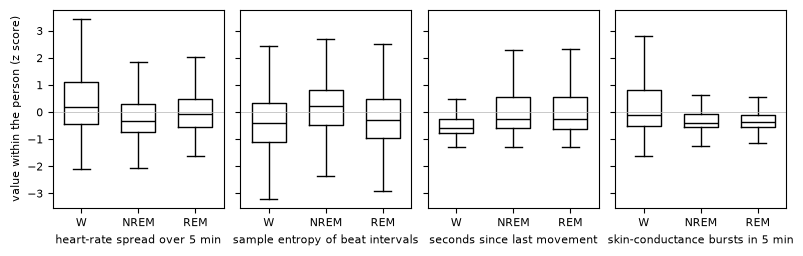

       heart-rate spread over 5 min  sample entropy of beat intervals  seconds since last movement  skin-conductance bursts in 5 min
stage                                                                                                                               
W                              0.18                             -0.40                        -0.58                             -0.13
NREM                          -0.34                              0.21                        -0.25                             -0.42
REM                           -0.06                             -0.30                        -0.25                             -0.37


In [3]:
show = [("hrmin", "hr5_std_z", "heart-rate spread over 5 min"),
        ("nonlin", "nl_sampen_z", "sample entropy of beat intervals"),
        ("still", "secs_since_move_z", "seconds since last movement"),
        ("eda", "eda_bursts5_z", "skin-conductance bursts in 5 min")]
order = ["W", "NREM", "REM"]
fig, axes = plt.subplots(1, 4, figsize=(8, 2.6), sharey=True)
for ax, (fam, col, label) in zip(axes, show):
    v = G[fam][col]
    data = [v[df.stage3 == st].dropna().to_numpy() for st in order]
    ax.boxplot(data, showfliers=False, widths=0.6, medianprops={"color": "k"})
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels(order); ax.axhline(0, color="0.7", lw=0.5)
    ax.set_xlabel(label)
axes[0].set_ylabel("value within the person (z score)")
plt.tight_layout(); plt.savefig(FIGS / "fig08_new_families_by_stage.png", dpi=150); plt.show()
print((pd.DataFrame({lab: G[f][c] for f, c, lab in show}).assign(stage=df.stage3).groupby("stage").median().loc[order]).round(2).to_string())

## 3. Do the families help the BiGRU?

Model: the BiGRU with balanced class weights from notebook 07, section 6. Same 5 folds split by person, same settings. The reference is that BiGRU with only our 10 features (`preds_bigru_balanced_5fold.csv`). Each run adds one family's within-person z-scored columns; the last run adds all four. HEAVY: about 2.5 minutes per run, 5 runs.

Numbers: a table per run, for all 35 people and for the 29 who had REM (people with no REM favour models that never predict REM; see notebook 07). The main number is the paired per-person change in macro F1 on the 29, against the reference.

Figure: one column per run. Each dot is one of the 29 people with REM: how much their macro F1 changed when the family was added. Above the dashed line = better with the family. The black bar is the median person.

heart rate over minutes: 7 columns added, 145s


nonlinear beat intervals: 5 columns added, 145s


stillness: 3 columns added, 144s


skin conductance: 5 columns added, 143s


all four: 20 columns added, 145s


                                        median_macro_f1  kappa_pooled  rem_f1  rem_recall  false_rem_on_nrem
people      run                                                                                             
all 35      reference (10 features)               0.426         0.227   0.178       0.352              0.317
            + heart rate over minutes             0.475         0.310   0.244       0.335              0.167
            + nonlinear beat intervals            0.478         0.325   0.242       0.335              0.170
            + stillness                           0.444         0.276   0.186       0.239              0.169
            + skin conductance                    0.439         0.241   0.164       0.254              0.221
            + all four                            0.480         0.335   0.249       0.342              0.168
29 with REM reference (10 features)               0.420         0.186   0.194       0.352              0.328
            + heart

  + nonlinear beat intervals   median +0.038  95% CI [-0.009, +0.076]  better 18 / worse 11
  + stillness                  median +0.018  95% CI [-0.024, +0.045]  better 18 / worse 11


  + skin conductance           median +0.008  95% CI [-0.020, +0.030]  better 16 / worse 13
  + all four                   median +0.052  95% CI [+0.026, +0.099]  better 22 / worse 7


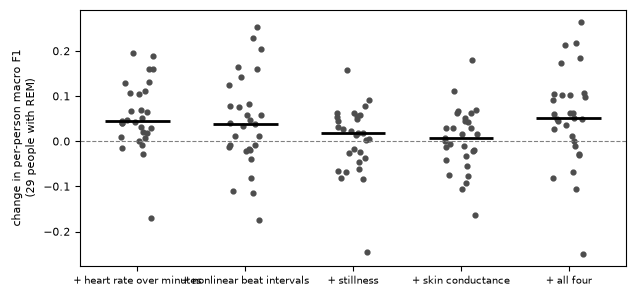

In [4]:
import warnings
from sklearn.metrics import cohen_kappa_score, f1_score
from splits import make_person_folds
from evaluation import make_xy, macro_f1_per_person, rem_rates
from metrics import paired_difference
from sequence import BiGRUSequence, make_sequences
folds = make_person_folds(people, n_folds=5, n_tune=4, seed=20261011)
Z = [c for c in df.columns if c.endswith("_z")]
had_rem = df.groupby("subject").stage3.agg(lambda s: (s == "REM").any())
with_rem = list(had_rem[had_rem].index)

def run_bigru(extra_name, extra):
    D = df.join(extra) if extra is not None else df
    cols = Z + (list(extra.columns) if extra is not None else [])
    X, y, s, idx = make_xy(D, cols)
    ep = D.loc[idx, "epoch"].to_numpy()
    parts = []
    for i, f in enumerate(folds):
        tr = np.isin(s, f["train"])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            med = np.nanmedian(X[tr], axis=0)
        seq = {q["subject"]: q for q in make_sequences(X, y, s, idx, ep, np.where(np.isnan(med), 0.0, med))}
        m = BiGRUSequence(weighting="balanced").fit([seq[q] for q in f["train"]], [seq[q] for q in f["tune"]])
        test = [seq[q] for q in f["test"]]
        for q, yh in zip(test, m.predict(test)):
            parts.append(pd.DataFrame({"subject": q["subject"], "row": q["row"], "y": q["y"], "yhat": yh, "fold": i}))
    p = pd.concat(parts, ignore_index=True)
    p.to_csv(DERIVED / f"preds_bigru_balanced_plus_{extra_name}_5fold.csv", index=False)
    return p

def summary(p):
    t = macro_f1_per_person(p); rr, fr = rem_rates(p)
    return {"median_macro_f1": t.macro_f1.median(), "kappa_pooled": cohen_kappa_score(p.y, p.yhat),
            "rem_f1": f1_score(p.y, p.yhat, labels=[2], average="macro"), "rem_recall": rr, "false_rem_on_nrem": fr}

ref = pd.read_csv(DERIVED / "preds_bigru_balanced_5fold.csv")
zcols = lambda g: [c for c in g.columns if c.endswith("_z")]
runs = {"heart rate over minutes": ("hrmin", G["hrmin"][zcols(G["hrmin"])]),
        "nonlinear beat intervals": ("nonlin", G["nonlin"][zcols(G["nonlin"])]),
        "stillness": ("still", G["still"][zcols(G["still"])]),
        "skin conductance": ("eda", G["eda"][zcols(G["eda"])]),
        "all four": ("all4", pd.concat([G[k][zcols(G[k])] for k in ["hrmin", "nonlin", "still", "eda"]], axis=1))}
P = {}
for label, (nm, extra) in runs.items():
    t0 = time.time(); P[label] = run_bigru(nm, extra)
    print(f"{label}: {extra.shape[1]} columns added, {time.time() - t0:.0f}s")

rows, deltas = [], {}
t_ref = macro_f1_per_person(ref[ref.subject.isin(with_rem)]).macro_f1
for who, keep in [("all 35", people), ("29 with REM", with_rem)]:
    rows.append({"people": who, "run": "reference (10 features)", **summary(ref[ref.subject.isin(keep)])})
    for label, p in P.items():
        rows.append({"people": who, "run": "+ " + label, **summary(p[p.subject.isin(keep)])})
print(pd.DataFrame(rows).set_index(["people", "run"]).round(3).to_string())
print("\nper person, 29 with REM, change against the reference:")
for label, p in P.items():
    t = macro_f1_per_person(p[p.subject.isin(with_rem)]).macro_f1
    deltas[label] = (t - t_ref).dropna(); d = paired_difference(t, t_ref)
    print(f"  + {label:26s} median {d['median']:+.3f}  95% CI [{d['lo']:+.3f}, {d['hi']:+.3f}]  "
          f"better {int((deltas[label] > 0).sum())} / worse {int((deltas[label] < 0).sum())}")

fig, ax = plt.subplots(figsize=(6.4, 3.0))
for i, (label, dl) in enumerate(deltas.items()):
    jit = np.random.default_rng(0).uniform(-0.15, 0.15, dl.size)
    ax.scatter(np.full(dl.size, i) + jit, dl, s=12, color="0.3")
    ax.hlines(dl.median(), i - 0.3, i + 0.3, color="k", lw=2)
ax.axhline(0, color="0.5", ls="--", lw=0.8)
ax.set_xticks(range(len(deltas))); ax.set_xticklabels(["+ " + k for k in deltas], fontsize=7)
ax.set_ylabel("change in per-person macro F1\n(29 people with REM)")
plt.tight_layout(); plt.savefig(FIGS / "fig08_families_in_bigru.png", dpi=150); plt.show()